In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
df = pd.read_csv("comparacion_modelos.csv")

In [34]:
df

,Unnamed: 0,model,accuracy,f1,f1_micro,f1_macro,tipo
0,0,swinv2-base-patch4-window16-256,0.989434,0.989440,0.989434,0.986394,Finetuneado
1,1,vit-base-patch16-224,0.987438,0.987449,0.987438,0.983497,Finetuneado
2,2,convnext-base-224,0.986897,0.986932,0.986897,0.983164,Finetuneado
3,3,beit-base-patch16-224,0.986273,0.986286,0.986273,0.982046,Finetuneado
4,4,dinov2-base,0.978577,0.978651,0.978577,0.972463,Finetuneado
5,5,Aleatorio ponderado (según distribución),0.324709,0.324376,0.324709,0.252881,Nulo
6,6,Aleatorio uniforme,0.252080,0.272777,0.252080,0.230795,Nulo
7,7,Clase mayoritaria,0.384318,0.213391,0.384318,0.138811,Nulo


## MÉTRICA F1 - Todos los modelos finetuneados vs. modelos nulos 

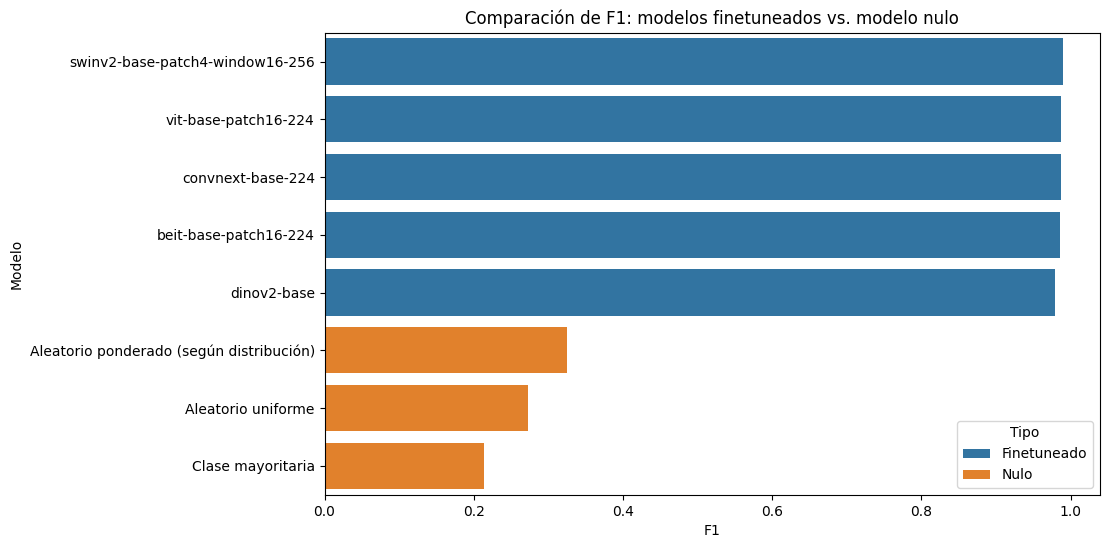

In [40]:
plt.figure(figsize=(10,6))
sns.barplot(x="f1", y="model", hue="tipo", data=df, dodge=False)
plt.title("Comparación de F1: modelos finetuneados vs. modelo nulo")
plt.xlabel("F1")
plt.ylabel("Modelo")
plt.legend(title="Tipo")
plt.show()

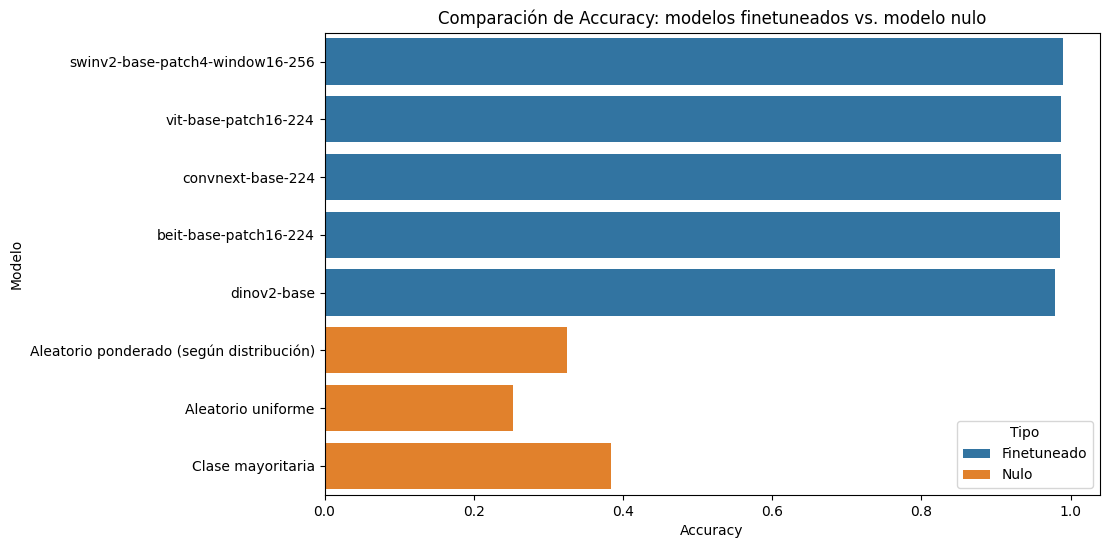

In [41]:
plt.figure(figsize=(10,6))
sns.barplot(x="accuracy", y="model", hue="tipo", data=df, dodge=False)
plt.title("Comparación de Accuracy: modelos finetuneados vs. modelo nulo")
plt.xlabel("Accuracy")
plt.ylabel("Modelo")
plt.legend(title="Tipo")
plt.show()

## Comparación por métrica: accuracy vs F1-macro

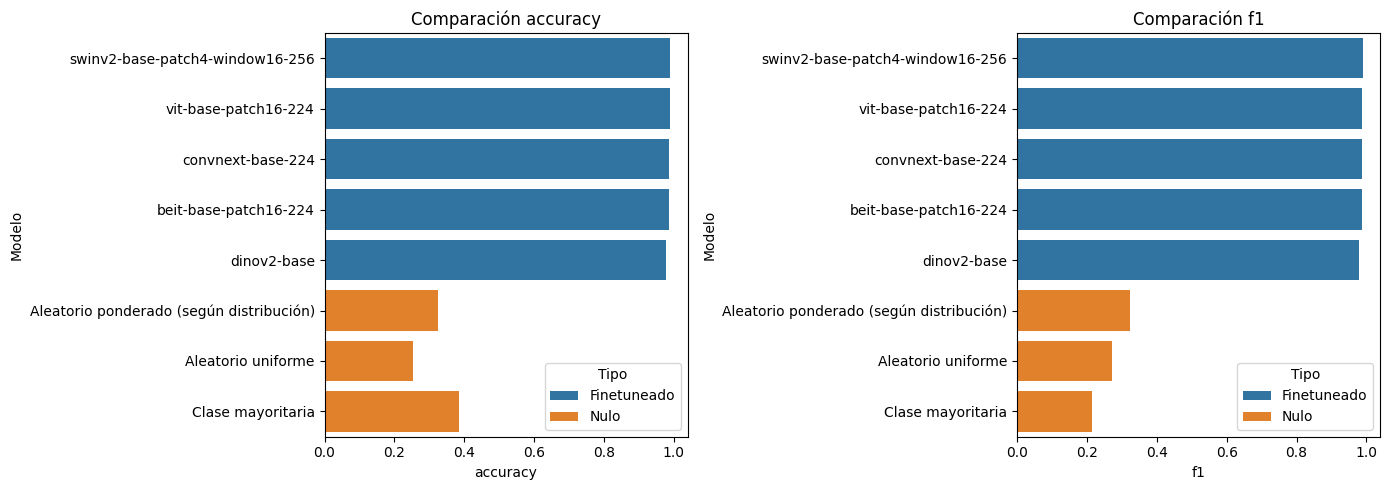

In [42]:
metrics = ["accuracy", "f1"]

fig, axes = plt.subplots(1, len(metrics), figsize=(14,5))

for i, metric in enumerate(metrics):
    sns.barplot(x=metric, y="model", hue="tipo", data=df, dodge=False, ax=axes[i])
    axes[i].set_title(f"Comparación {metric}")
    axes[i].set_xlabel(metric)
    axes[i].set_ylabel("Modelo")
    axes[i].legend(title="Tipo")

plt.tight_layout()
plt.show()

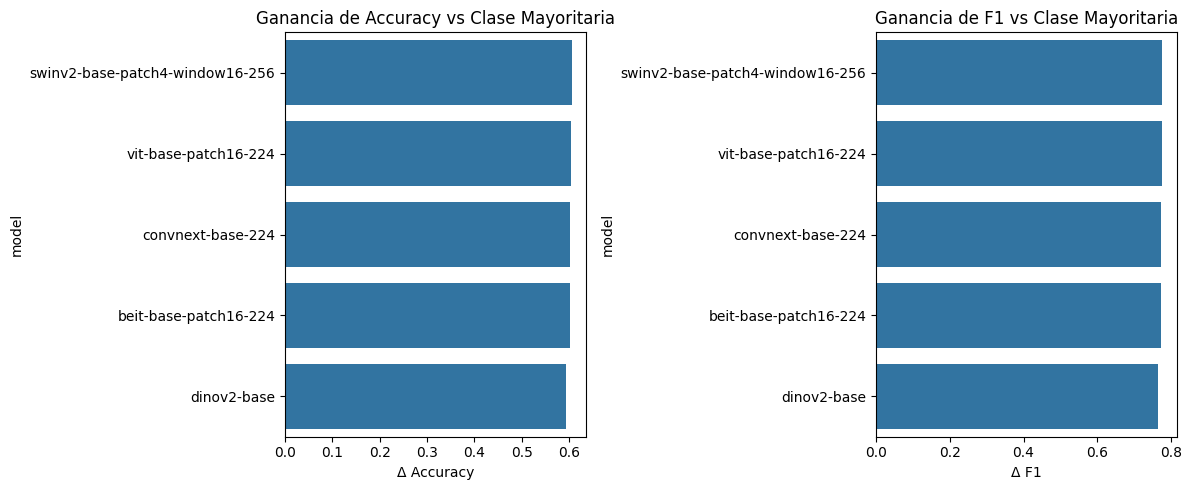

In [44]:
df_baselines_only = df[df["tipo"]=="Nulo"].set_index("model")
df_finetune = df[df["tipo"]=="Finetuneado"].copy()

# Suponiendo que usaremos baseline más frecuente
baseline_acc = df_baselines_only.loc["Clase mayoritaria", "accuracy"]
baseline_f1 = df_baselines_only.loc["Clase mayoritaria", "f1"]

df_finetune["gain_accuracy"] = df_finetune["accuracy"] - baseline_acc
df_finetune["gain_f1"] = df_finetune["f1"] - baseline_f1

# Visualización
fig, axes = plt.subplots(1,2, figsize=(12,5))
sns.barplot(x="gain_accuracy", y="model", data=df_finetune, ax=axes[0])
axes[0].set_title("Ganancia de Accuracy vs Clase Mayoritaria")
axes[0].set_xlabel("Δ Accuracy")

sns.barplot(x="gain_f1", y="model", data=df_finetune, ax=axes[1])
axes[1].set_title("Ganancia de F1 vs Clase Mayoritaria")
axes[1].set_xlabel("Δ F1")

plt.tight_layout()
plt.show()